# 05 — Chọn mô hình nền cho stacking

Tinh chỉnh 7 mô hình thư viện, so sánh lỗi giữa các cặp/bộ ba và chọn **bộ ba ứng viên** cho stacking. Phần mô hình tự viết nằm ở các notebook trước; `Softmax_sklearn` ở đây là LogisticRegression của sklearn.

Chọn theo **soft voting accuracy validation**, F1 macro phá hòa; nếu vẫn hòa thì dùng thứ tự tên combo để kết quả xác định. Độ trùng lỗi dùng phân tích bổ sung. Chưa thể khẳng định bộ ba này tối ưu cho stacking.

Chạy từ thư mục gốc đồ án hoặc `notebooks/`. SVM với `probability=True` và các MLP có thể chạy lâu trên CPU; không dùng GPU. Hình/bảng/cấu hình lưu tại `results/select_base_models/`.


## 1. Import và cấu hình


In [1]:
import json
from pathlib import Path
from itertools import combinations
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from joblib import dump

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
OUTPUT = ROOT / 'results' / 'select_base_models'
OUTPUT.mkdir(parents=True, exist_ok=True)
from src.data import load_prepared_mnist
SEED = 42
from sklearn.base import clone
import warnings


## 2. Chia dữ liệu

Giữ 10.000 validation bên ngoài để chọn bộ ba. Trong 50.000 train, chia 40.000 fit / 10.000 tuning để chọn tham số từng mô hình, sau đó refit trên đủ 50.000 train. Không sử dụng test; phần EDA không lặp lại ở đây.


In [2]:
X, y, _, _ = load_prepared_mnist()
X, y = np.asarray(X, dtype=np.float32), np.asarray(y, dtype=int)
train_idx, val_idx = train_test_split(np.arange(len(y)), test_size=10000, stratify=y, random_state=SEED)
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_fit, X_tune, y_fit, y_tune = train_test_split(X_train, y_train, test_size=10000, stratify=y_train, random_state=SEED)
print('Refit train:', X_train.shape, 'Validation chọn bộ ba:', X_val.shape)
print('Fit tuning:', X_fit.shape, 'Holdout tuning:', X_tune.shape)


Refit train: (50000, 784) Validation chọn bộ ba: (10000, 784)
Fit tuning: (40000, 784) Holdout tuning: (10000, 784)


## 3. Tuning và refit từng mô hình

Giữ lưới khảo sát ban đầu. Chọn tham số theo accuracy trên holdout tuning, F1 macro phá hòa; nếu cùng điểm giữ cấu hình đứng trước trong lưới. Đây là holdout tuning, không phải cross-validation.

SVM tuning theo `predict`; khi refit bật `probability=True` để lấy xác suất voting. `SVC.predict` có thể khác argmax của `predict_proba`; thống kê lỗi mô hình đơn dùng `predict`, voting dùng xác suất đã xếp cùng thứ tự lớp 0–9. Các xác suất không được hiệu chỉnh chung giữa các họ mô hình.

Cảnh báo hội tụ được in và lưu trong bảng; mô hình có cảnh báo cần được xem xét trước khi kết luận. Thời gian fit tuning, refit, predict và predict_proba được tách riêng; mỗi thao tác đo một lần.


Tuning: SVM
{'C': 1} F1=0.9744 
{'C': 3} F1=0.9791 
{'C': 10} F1=0.9792 
Cảnh báo: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
SVM hoàn tất; validation accuracy: 0.9826
Tuning: Softmax_sklearn
{'C': 0.1} F1=0.9168 
{'C': 1} F1=0.9164 
Cảnh báo: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
{'C': 10} F1=0.9123 Có cảnh báo
Softmax_sklearn hoàn tất; validation accuracy: 0.9214
Tuning: RandomForest
{'min_samples_leaf': 1} F1=0.9646 
{'min_samples_leaf': 2} F1=0.9635 

,model,params,f1_macro,accuracy,fit_seconds,warning
0,SVM,{'C': 1},0.9744,0.9746,136.9069,
1,SVM,{'C': 3},0.9791,0.9793,128.1281,
2,SVM,{'C': 10},0.9792,0.9794,122.9367,
3,Softmax_sklearn,{'C': 0.1},0.9168,0.9180,109.1099,
4,Softmax_sklearn,{'C': 1},0.9164,0.9175,203.8268,
5,Softmax_sklearn,{'C': 10},0.9123,0.9135,258.9066,lbfgs failed to converge after 300 iteration(s...
6,RandomForest,{'min_samples_leaf': 1},0.9646,0.9650,5.5503,
7,RandomForest,{'min_samples_leaf': 2},0.9635,0.9639,5.5234,
8,RandomForest,{'min_samples_leaf': 4},0.9600,0.9604,4.9897,
9,KNN,{'n_neighbors': 3},0.9692,0.9694,0.0146,


,model,params,accuracy,f1_macro,precision_macro,recall_macro,n_errors,tuning_fit_seconds,fit_seconds,predict_seconds,proba_seconds,warning
5,MLP512,{'alpha': 0.01},0.9828,0.9827,0.9827,0.9827,172,1595.2377,662.0889,0.1646,0.1342,Stochastic Optimizer: Maximum iterations (60) ...
0,SVM,{'C': 10},0.9826,0.9825,0.9825,0.9825,174,387.9717,923.0227,48.6207,47.6164,The `probability` parameter was deprecated in ...
6,MLP256_128,{'alpha': 0.01},0.9819,0.9818,0.9818,0.9819,181,905.3065,360.5463,0.0396,0.0466,Stochastic Optimizer: Maximum iterations (60) ...
3,KNN,{'n_neighbors': 3},0.9720,0.9720,0.9725,0.9716,280,0.0707,0.0676,5.6331,5.6704,
4,ExtraTrees,{'min_samples_leaf': 1},0.9709,0.9708,0.9708,0.9708,291,17.4779,7.9193,0.1738,0.1457,
2,RandomForest,{'min_samples_leaf': 1},0.9669,0.9668,0.9668,0.9668,331,16.0633,7.0553,0.2048,0.1486,
1,Softmax_sklearn,{'C': 0.1},0.9214,0.9205,0.9207,0.9205,786,571.8433,235.5789,0.0092,0.0059,


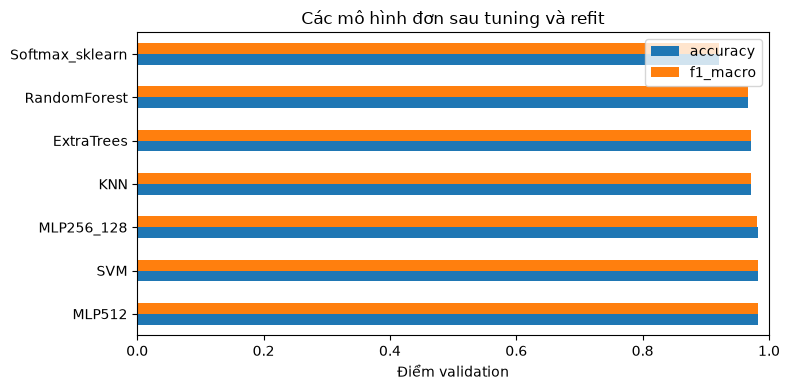

In [3]:
base = {
    'SVM': SVC(kernel='rbf', gamma='scale', cache_size=2000, random_state=SEED),
    'Softmax_sklearn': LogisticRegression(solver='lbfgs', max_iter=300, tol=1e-4),
    'RandomForest': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    'KNN': KNeighborsClassifier(weights='distance', n_jobs=-1),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    'MLP512': MLPClassifier(hidden_layer_sizes=(512,), solver='adam', batch_size=256,
        learning_rate_init=0.001, max_iter=60, early_stopping=False, tol=0,
        n_iter_no_change=61, random_state=SEED),
    'MLP256_128': MLPClassifier(hidden_layer_sizes=(256,128), solver='adam', batch_size=256,
        learning_rate_init=0.001, max_iter=60, early_stopping=False, tol=0,
        n_iter_no_change=61, random_state=SEED)
}
grids = {
    'SVM': [{'C': v} for v in [1, 3, 10]],
    'Softmax_sklearn': [{'C': v} for v in [0.1, 1, 10]],
    'RandomForest': [{'min_samples_leaf': v} for v in [1, 2, 4]],
    'KNN': [{'n_neighbors': v} for v in [3, 5, 7]],
    'ExtraTrees': [{'min_samples_leaf': v} for v in [1, 2, 4]],
    'MLP512': [{'alpha': v} for v in [0.001, 0.01, 0.1]],
    'MLP256_128': [{'alpha': v} for v in [0.001, 0.01, 0.1]]
}

def fit_timed(model, X, y):
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(X, y)
    messages = ' | '.join(str(w.message) for w in caught)
    if messages: print('Cảnh báo:', messages, flush=True)
    return time.perf_counter() - t0, messages

models, best_params, tuning_rows, rows = {}, {}, [], []
proba, pred, errors = {}, {}, {}
for name, estimator in base.items():
    print('Tuning:', name, flush=True)
    scores, tuning_s = [], 0
    for params in grids[name]:
        model = clone(estimator).set_params(**params)
        seconds, message = fit_timed(model, X_fit, y_fit)
        tuning_s += seconds
        yp = model.predict(X_tune)
        f1, acc = f1_score(y_tune, yp, average='macro'), accuracy_score(y_tune, yp)
        scores.append((acc, f1))
        tuning_rows.append(dict(model=name, params=str(params), f1_macro=f1,
            accuracy=acc, fit_seconds=seconds, warning=message))
        print(params, f'F1={f1:.4f}', 'Có cảnh báo' if message else '', flush=True)
    best_params[name] = grids[name][max(range(len(scores)), key=lambda i: scores[i])]
    model = clone(estimator).set_params(**best_params[name])
    if name == 'SVM': model.set_params(probability=True)
    fit_s, message = fit_timed(model, X_train, y_train)
    models[name] = model
    t0 = time.perf_counter()
    pred[name] = model.predict(X_val)
    predict_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    proba[name] = model.predict_proba(X_val)[:, np.argsort(model.classes_)]
    proba_s = time.perf_counter() - t0
    errors[name] = pred[name] != y_val
    precision, recall, _, _ = precision_recall_fscore_support(y_val, pred[name], average='macro', zero_division=0)
    rows.append(dict(model=name, params=str(best_params[name]),
        accuracy=accuracy_score(y_val, pred[name]), f1_macro=f1_score(y_val, pred[name], average='macro'),
        precision_macro=precision, recall_macro=recall,
        n_errors=int(errors[name].sum()), tuning_fit_seconds=tuning_s, fit_seconds=fit_s,
        predict_seconds=predict_s, proba_seconds=proba_s, warning=message))
    print(name, 'hoàn tất; validation accuracy:', rows[-1]['accuracy'], flush=True)
tuning_results = pd.DataFrame(tuning_rows)
singles = pd.DataFrame(rows).sort_values(['accuracy', 'f1_macro'], ascending=False)
display(tuning_results.round(4))
display(singles.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
singles.set_index('model')[['accuracy', 'f1_macro']].plot.barh(ax=ax, xlim=(0, 1))
ax.set(xlabel='Điểm validation', ylabel='', title='Các mô hình đơn sau tuning và refit')
fig.tight_layout(); fig.savefig(OUTPUT / 'single_models.png', dpi=300); plt.show()

## 4. So sánh cặp và bộ ba

- **common_errors:** số ảnh mà mọi mô hình trong nhóm đều dự đoán sai, không yêu cầu cùng nhãn sai.
- **overlap_ratio:** common_errors chia cho số lỗi ít nhất trong nhóm; thấp nghĩa là ít lỗi chung tương đối với mô hình ít lỗi nhất. Không phải tỷ lệ dự đoán giống nhau.
- **oracle_accuracy:** tỷ lệ ảnh có ít nhất một mô hình dự đoán đúng. Đây là kết quả của bộ chọn giả định biết nhãn thật, không phải accuracy triển khai và không phải giới hạn trên tổng quát của soft voting/stacking.
- **soft voting:** trung bình xác suất với trọng số bằng nhau rồi lấy argmax.
- **gain_over_best / gain_over_global_best:** chênh accuracy so với model đơn tốt nhất trong nhóm / toàn bộ ứng viên. Giá trị lưu dạng tỷ lệ, nhân 100 để đổi sang điểm phần trăm.

Một nhóm có overlap thấp nhưng các mô hình yếu vẫn có thể voting kém. Xếp hạng dựa trên voting thực tế, không chỉ dựa vào overlap.


In [4]:
# Trùng lỗi = mọi model đều sai trên cùng ảnh, có thể khác nhãn sai.
# Oracle = tỷ lệ có ít nhất một model đúng.
def compare_combos(size):
    rows = []
    for combo in combinations(models, size):
        common = np.logical_and.reduce([errors[n] for n in combo]).sum()
        least = min(errors[n].sum() for n in combo)
        vote = np.mean([proba[n] for n in combo], axis=0).argmax(1)
        best_single = max(accuracy_score(y_val, pred[n]) for n in combo)
        rows.append(dict(combo=' + '.join(combo), common_errors=int(common),
            overlap_ratio=common / least if least else np.nan,
            oracle_accuracy=1 - common / len(y_val),
            voting_accuracy=accuracy_score(y_val, vote),
            voting_f1=f1_score(y_val, vote, average='macro'),
            gain_over_best=accuracy_score(y_val, vote) - best_single,
            gain_over_global_best=accuracy_score(y_val, vote) - singles.accuracy.max()))
    return pd.DataFrame(rows).sort_values(['voting_accuracy', 'voting_f1', 'combo'], ascending=[False, False, True]).reset_index(drop=True)

pairs, triples = compare_combos(2), compare_combos(3)
print(f'{len(pairs)} cặp; hiển thị 10 cặp đầu:'); display(pairs.head(10).round(4))
print(f'{len(triples)} bộ ba; hiển thị 10 bộ ba đầu:'); display(triples.head(10).round(4))

21 cặp; hiển thị 10 cặp đầu:


,combo,common_errors,overlap_ratio,oracle_accuracy,voting_accuracy,voting_f1,gain_over_best,gain_over_global_best
0,SVM + MLP512,119,0.6919,0.9881,0.9846,0.9845,0.0018,0.0018
1,SVM + MLP256_128,117,0.6724,0.9883,0.9838,0.9837,0.0012,0.0010
2,SVM + ExtraTrees,129,0.7414,0.9871,0.9837,0.9837,0.0011,0.0009
3,SVM + RandomForest,135,0.7759,0.9865,0.9832,0.9831,0.0006,0.0004
4,MLP512 + MLP256_128,129,0.7500,0.9871,0.9832,0.9831,0.0004,0.0004
5,ExtraTrees + MLP512,123,0.7151,0.9877,0.9831,0.9830,0.0003,0.0003
6,RandomForest + MLP512,131,0.7616,0.9869,0.9828,0.9827,0.0000,0.0000
7,ExtraTrees + MLP256_128,119,0.6575,0.9881,0.9826,0.9825,0.0007,-0.0002
8,RandomForest + MLP256_128,129,0.7127,0.9871,0.9825,0.9824,0.0006,-0.0003
9,KNN + MLP256_128,91,0.5028,0.9909,0.9810,0.9810,-0.0009,-0.0018


35 bộ ba; hiển thị 10 bộ ba đầu:


,combo,common_errors,overlap_ratio,oracle_accuracy,voting_accuracy,voting_f1,gain_over_best,gain_over_global_best
0,SVM + KNN + MLP512,82,0.4767,0.9918,0.9853,0.9853,0.0025,0.0025
1,SVM + KNN + MLP256_128,81,0.4655,0.9919,0.9852,0.9851,0.0026,0.0024
2,KNN + MLP512 + MLP256_128,77,0.4477,0.9923,0.9850,0.9849,0.0022,0.0022
3,SVM + MLP512 + MLP256_128,103,0.5988,0.9897,0.9845,0.9844,0.0017,0.0017
4,SVM + RandomForest + MLP512,97,0.5640,0.9903,0.9845,0.9844,0.0017,0.0017
5,SVM + ExtraTrees + MLP512,94,0.5465,0.9906,0.9844,0.9843,0.0016,0.0016
6,SVM + RandomForest + MLP256_128,98,0.5632,0.9902,0.9840,0.9839,0.0014,0.0012
7,ExtraTrees + MLP512 + MLP256_128,99,0.5756,0.9901,0.9840,0.9839,0.0012,0.0012
8,SVM + ExtraTrees + MLP256_128,92,0.5287,0.9908,0.9839,0.9838,0.0013,0.0011
9,RandomForest + MLP512 + MLP256_128,104,0.6047,0.9896,0.9839,0.9838,0.0011,0.0011


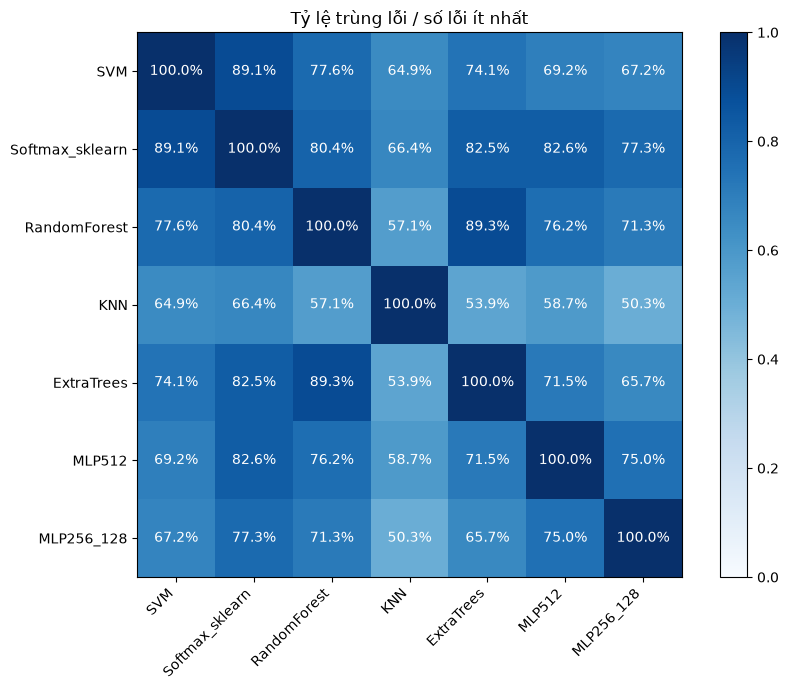

In [5]:
names = list(models)
heat = np.full((len(names), len(names)), np.nan)
for i, a in enumerate(names):
    for j, b in enumerate(names):
        least = min(errors[a].sum(), errors[b].sum())
        if least: heat[i, j] = (errors[a] & errors[b]).sum() / least
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(heat, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(len(names)), names, rotation=45, ha='right')
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f'{heat[i,j]:.1%}', ha='center', va='center',
            color='white' if heat[i,j] > 0.5 else 'black')
ax.set_title('Tỷ lệ trùng lỗi / số lỗi ít nhất')
fig.colorbar(im, ax=ax)
fig.tight_layout(); fig.savefig(OUTPUT / 'error_overlap.png', dpi=300); plt.show()


**Nhận xét:** đọc heatmap cùng bảng mô hình đơn và bảng voting. Đường chéo thường là 100% vì một mô hình trùng toàn bộ lỗi với chính nó; nhóm không có lỗi ở mẫu số sẽ nhận NaN thay vì chia cho 0.


## 5. Chọn bộ ba ứng viên

Bộ ba đứng đầu được dùng cho bước stacking tiếp theo, kể cả khi voting chưa vượt model đơn tốt nhất; cần báo cáo chênh lệch một cách trung thực. Kết quả trên validation đã dùng chọn nhóm có thể lạc quan. Không điều chỉnh nhóm theo điểm test.


Bộ ba đề xuất: ['SVM', 'KNN', 'MLP512']
Soft voting accuracy=98.53%; F1 macro=0.9853
Chênh với model đơn tốt nhất toàn nhóm: +0.25 điểm phần trăm
Số ảnh cả ba cùng sai: 82
Tỷ lệ trùng lỗi / số lỗi ít nhất: 47.67%


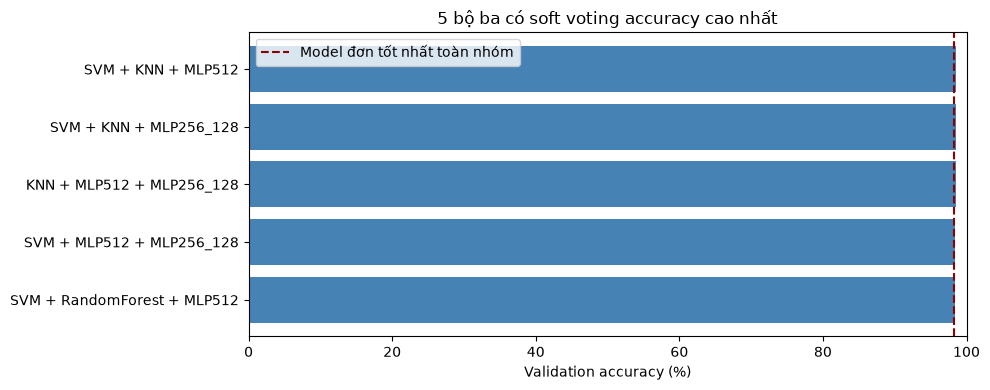

In [6]:
selected_row = triples.iloc[0]
selected = selected_row.combo.split(' + ')
print('Bộ ba đề xuất:', selected)
print(f'Soft voting accuracy={selected_row.voting_accuracy:.2%}; F1 macro={selected_row.voting_f1:.4f}')
print(f'Chênh với model đơn tốt nhất toàn nhóm: {selected_row.gain_over_global_best*100:+.2f} điểm phần trăm')
print('Số ảnh cả ba cùng sai:', int(selected_row.common_errors))
print(f'Tỷ lệ trùng lỗi / số lỗi ít nhất: {selected_row.overlap_ratio:.2%}')
fig, ax = plt.subplots(figsize=(10, 4))
top = triples.head(5).iloc[::-1]
ax.barh(top.combo, top.voting_accuracy * 100, color='steelblue')
ax.axvline(singles.accuracy.max() * 100, color='darkred', linestyle='--', label='Model đơn tốt nhất toàn nhóm')
ax.set(xlabel='Validation accuracy (%)', title='5 bộ ba có soft voting accuracy cao nhất', xlim=(0, 100))
ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT / 'top_triples.png', dpi=300, bbox_inches='tight'); plt.show()


**Giới hạn:** chọn theo voting là một tiêu chí thực nghiệm gọn để đề xuất nhóm, không bảo đảm nhóm tốt nhất cho AdaBoost meta-learner. Notebook 06 cần tạo OOF bằng training fold cho từng base model rồi mới fit meta-model; không dùng dự đoán in-sample thay cho OOF.


## 6. Lưu kết quả cho báo cáo và stacking

Lưu đầy đủ 21 cặp/35 bộ ba trong CSV, dù chỉ hiển thị top 10. `selected_estimators.joblib` chứa **bản clone chưa fit** với cấu hình đã chọn; notebook 06 nạp đúng file này để tạo OOF, không khai báo cứng một bộ ba khác. `split_indices.npz` lưu chỉ số trên 60.000 ảnh train gốc.

Trong notebook 06, sau khi import và xác định ROOT:

```python
from joblib import load
base_models = load(ROOT / 'results/select_base_models/selected_estimators.joblib')
```

Chỉ nạp joblib do chính bạn tạo. Chạy lại ghi đè các file cùng tên.


In [7]:
singles.to_csv(OUTPUT / 'singles.csv', index=False)
pairs.to_csv(OUTPUT / 'pairs.csv', index=False)
triples.to_csv(OUTPUT / 'triples.csv', index=False)
np.savez_compressed(OUTPUT / 'validation_proba.npz', y_val=y_val, **proba)
(OUTPUT / 'selected_models.txt').write_text('\n'.join(selected), encoding='utf-8')
print('Đã lưu:', OUTPUT)
tuning_results.to_csv(OUTPUT / 'tuning.csv', index=False)
(OUTPUT / 'best_params.json').write_text(json.dumps(best_params, indent=2), encoding='utf-8')
selected_estimators = {name: clone(models[name]) for name in selected}
dump(selected_estimators, OUTPUT / 'selected_estimators.joblib')
np.savez_compressed(OUTPUT / 'split_indices.npz', train_idx=train_idx, val_idx=val_idx, seed=SEED)
pd.DataFrame(heat, index=names, columns=names).to_csv(OUTPUT / 'error_overlap.csv')
selection_config = dict(seed=SEED, classes=list(range(10)), train_samples=len(y_train), validation_samples=len(y_val),
    selected_models=selected, selection='voting_accuracy, voting_f1; hoa thi ten combo',
    voting_accuracy=float(selected_row.voting_accuracy), voting_f1=float(selected_row.voting_f1),
    overlap_ratio=float(selected_row.overlap_ratio), common_errors=int(selected_row.common_errors),
    selected_params={name: selected_estimators[name].get_params() for name in selected})
(OUTPUT / 'selection.json').write_text(json.dumps(selection_config, ensure_ascii=False, indent=2), encoding='utf-8')
print('Dùng selected_estimators.joblib trong notebook 06; đây là các estimator CHƯA fit.')


Đã lưu: d:\Nhận dạng mẫu\mnist\results\select_base_models
Dùng selected_estimators.joblib trong notebook 06; đây là các estimator CHƯA fit.
